# Aula 23 - Notebook: Protocolo de Árvore Geradora (STP / RSTP) na Rede Industrial da Fábrica de Paçoca

**Disciplina:** ECAA08 — Automática (2026.2) — UNIFEI
**Projeto:** SCADA-Core Automática / Linha de Produção de Paçoca — **Equipe:** Grupo 7

Este notebook modela a rede Ethernet industrial (camada 2) que interliga a Sala de Controle, os quatro CLPs da linha (CLP 01 a CLP 04), o Laboratório de Qualidade (base do AGV da Aula 17) e o Galpão B de Expedição (WMS da Aula 18) como um grafo não-dirigido ponderado $G = (V, E, w)$.

### Roteiro
1. Modelagem da topologia física **v1** (anel de fibra seguindo a linha de produção + backbone de 10 Gbps até o forno de torra + prédios externos em cobre legado).
2. Implementação do **RSTP (IEEE 802.1w)** do zero: eleição do *Root Bridge*, *Root Path Cost*, papéis e estados de porta.
3. **RSTP não é Kruskal/Prim:** comparação entre a árvore de caminhos mínimos até a raiz (SPT, que o RSTP constrói) e a Árvore Geradora Mínima (MST) da Aula 19.
4. **Falha 1:** rompimento do backbone `SW-SCADA ↔ SW-S200` (forno de torra).
5. **Falha 2:** perda do próprio *Root Bridge* — detecção de **ponto de articulação** (Tarjan) e particionamento da rede.
6. **Correção de projeto (topologia v2)** e **teste de contingência N-1** exaustivo (toda falha simples de enlace ou de switch).
7. Impacto do tempo de convergência (STP × RSTP × MRP) sobre o ciclo de supervisão e a rastreabilidade da produção.

### 1. Modelagem da Topologia Física v1

**Vértices (switches gerenciáveis L2).** O *Bridge ID* é a tupla $\text{BID} = (\text{priority}, \text{MAC})$; o menor BID vence a eleição de raiz.

* `SW-SCADA` — Sala de Controle (servidores SCADA, historiador, IHMs das Telas 01–04). Prioridade **4096** → raiz primária.
* `SW-S200` — Torra e Despeliculagem (CLP 02, forno `TT-201/TS-201/XV-201`, selecionadora óptica com câmeras RGB). Prioridade **8192** → raiz secundária: é o setor de maior risco (gás + 160 °C) e o de maior tráfego (imagens).
* `SW-S100`, `SW-S300`, `SW-S400` — CLP 01 (recepção/limpeza), CLP 03 (dosagem/moagem) e CLP 04 (prensa, `VS-401`, `MD-401`, embalagem). Prioridade padrão 32768.
* `SW-LAB` — Laboratório de Qualidade (liberação de lotes, ponto de acesso Wi-Fi do AGV de amostragem). Prioridade 32768.
* `SW-EXP` — Galpão B / Expedição (WMS de endereçamento das ruas 1–4, docas). Prioridade 32768.

**Arestas (enlaces físicos)** com custo IEEE 802.1w: 10 Gbps = 2.000, 1 Gbps = 20.000, 100 Mbps = 200.000.
O anel principal de 1 Gbps acompanha a própria linha de produção (S100 → S200 → S300 → S400) e fecha na Sala de Controle. Os prédios externos (Lab e Galpão B) chegam à Sala de Controle por **cabos de cobre legados de 100 Mbps**, e entre si por uma fibra de 1 Gbps instalada depois.

In [1]:
import heapq
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

CUSTO_10G, CUSTO_1G, CUSTO_100M = 2_000, 20_000, 200_000

SWITCHES = {
    "SW-SCADA": {"local": "Sala de Controle (SCADA/Historiador)",   "priority": 4096,  "mac": "00:1B:1B:07:00:01"},
    "SW-S100":  {"local": "Setor 100 - Recepção/Limpeza (CLP 01)",  "priority": 32768, "mac": "00:1B:1B:07:01:00"},
    "SW-S200":  {"local": "Setor 200 - Torra/Despel. (CLP 02)",      "priority": 8192,  "mac": "00:1B:1B:07:02:00"},
    "SW-S300":  {"local": "Setor 300 - Dosagem/Moagem (CLP 03)",     "priority": 32768, "mac": "00:1B:1B:07:03:00"},
    "SW-S400":  {"local": "Setor 400 - Prensa/Embalagem (CLP 04)",   "priority": 32768, "mac": "00:1B:1B:07:04:00"},
    "SW-LAB":   {"local": "Laboratório de Qualidade + AP do AGV",    "priority": 32768, "mac": "00:1B:1B:07:0A:00"},
    "SW-EXP":   {"local": "Galpão B - Expedição/WMS",                "priority": 32768, "mac": "00:1B:1B:07:0B:00"},
}

# (u, v, custo IEEE 802.1w, descrição física)
ENLACES_V1 = [
    ("SW-SCADA", "SW-S200", CUSTO_10G,  "10 Gbps fibra - backbone do forno/selecionadora óptica"),
    ("SW-SCADA", "SW-S100", CUSTO_1G,   "1 Gbps fibra - anel principal"),
    ("SW-S100",  "SW-S200", CUSTO_1G,   "1 Gbps fibra - anel (recepção -> torra)"),
    ("SW-S200",  "SW-S300", CUSTO_1G,   "1 Gbps fibra - anel (torra -> moagem)"),
    ("SW-S300",  "SW-S400", CUSTO_1G,   "1 Gbps fibra - anel (moagem -> prensa)"),
    ("SW-S400",  "SW-SCADA", CUSTO_1G,  "1 Gbps fibra - anel (fechamento)"),
    ("SW-SCADA", "SW-LAB",  CUSTO_100M, "100 Mbps cobre legado"),
    ("SW-SCADA", "SW-EXP",  CUSTO_100M, "100 Mbps cobre legado"),
    ("SW-LAB",   "SW-EXP",  CUSTO_1G,   "1 Gbps fibra entre prédios externos"),
]


class RedeL2:
    # Grafo não-dirigido ponderado G = (V, E, w) com lista de adjacência.
    def __init__(self, switches, enlaces):
        self.nos = {n: dict(a) for n, a in switches.items()}
        self.enlaces = [(u, v, c, d) for (u, v, c, d) in enlaces]
        self.adj = {n: {} for n in self.nos}
        for u, v, c, _ in self.enlaces:
            self.adj[u][v] = c
            self.adj[v][u] = c

    def bid(self, n):
        return (self.nos[n]["priority"], self.nos[n]["mac"])

    def custo(self, u, v):
        return self.adj[u][v]

    def sem_enlace(self, u, v):
        # Cópia da rede sem o enlace u-v (rompimento físico).
        restantes = [e for e in self.enlaces if {e[0], e[1]} != {u, v}]
        return RedeL2(self.nos, restantes)

    def sem_switch(self, x):
        # Cópia da rede sem o switch x (perda total do equipamento).
        nos = {n: a for n, a in self.nos.items() if n != x}
        restantes = [e for e in self.enlaces if x not in (e[0], e[1])]
        return RedeL2(nos, restantes)

    def com_enlace(self, u, v, c, d):
        return RedeL2(self.nos, self.enlaces + [(u, v, c, d)])

    def componentes(self):
        vistos, comps = set(), []
        for s in sorted(self.nos):
            if s in vistos:
                continue
            pilha, comp = [s], set()
            while pilha:
                x = pilha.pop()
                if x in comp:
                    continue
                comp.add(x)
                pilha.extend(y for y in self.adj[x] if y not in comp)
            vistos |= comp
            comps.append(comp)
        return comps


rede_v1 = RedeL2(SWITCHES, ENLACES_V1)
n, m = len(rede_v1.nos), len(rede_v1.enlaces)
print(f"Topologia v1: |V| = {n} switches, |E| = {m} enlaces físicos")
print(f"Número ciclomático (ciclos independentes) = |E| - |V| + 1 = {m - n + 1}")
print(f"Enlaces que o RSTP terá de bloquear para obter uma árvore: |E| - (|V| - 1) = {m - (n - 1)}")

Topologia v1: |V| = 7 switches, |E| = 9 enlaces físicos
Número ciclomático (ciclos independentes) = |E| - |V| + 1 = 3
Enlaces que o RSTP terá de bloquear para obter uma árvore: |E| - (|V| - 1) = 3


### 2. Implementação do RSTP (IEEE 802.1w)

A função `executar_rstp` reproduz o estado **convergido** do protocolo em cada componente conexo da rede:

1. **Eleição do Root Bridge:** menor $\text{BID} = (\text{priority}, \text{MAC})$.
2. **Root Path Cost:** custo mínimo de cada switch até a raiz (Dijkstra — Aula 14 — sobre os custos 802.1w).
3. **Root Port (RP):** em cada switch não-raiz, a porta que minimiza $(\text{custo até a raiz via vizinho}, \text{BID do vizinho})$ — o BID do vizinho é o critério de desempate da norma.
4. **Designated Port (DP):** em cada enlace, a extremidade do switch com menor $(\text{Root Path Cost}, \text{BID})$.
5. **Alternate Port (AP):** extremidade que não é RP nem DP; fica em *Discarding* e guarda um caminho pré-calculado para a raiz.

In [2]:
def executar_rstp(rede):
    # Retorna uma lista de resultados, um por componente conexo (cada ilha elege a sua raiz).
    resultados = []
    for comp in rede.componentes():
        raiz = min(comp, key=rede.bid)

        # Dijkstra a partir da raiz
        dist = {x: float("inf") for x in comp}
        dist[raiz] = 0
        heap = [(0, raiz)]
        while heap:
            d, u = heapq.heappop(heap)
            if d > dist[u]:
                continue
            for v, c in rede.adj[u].items():
                if d + c < dist[v]:
                    dist[v] = d + c
                    heapq.heappush(heap, (dist[v], v))

        # Root Port: vizinho que minimiza (custo via vizinho, BID do vizinho)
        pai = {raiz: None}
        for x in comp - {raiz}:
            pai[x] = min(rede.adj[x], key=lambda y: (dist[y] + rede.adj[x][y], rede.bid(y)))

        ativas, bloqueadas, linhas = [], [], []
        for u, v, c, desc in rede.enlaces:
            if u not in comp:
                continue
            if pai.get(v) == u or pai.get(u) == v:
                filho, mae = (v, u) if pai.get(v) == u else (u, v)
                papel = {mae: "DP [Forwarding]", filho: "RP [Forwarding]"}
                ativas.append((u, v))
                status = "ATIVO (árvore T)"
            else:
                # Enlace que fecha ciclo: lado de menor (custo, BID) é Designated; o outro é Alternate
                desig = min((u, v), key=lambda x: (dist[x], rede.bid(x)))
                alt = v if desig == u else u
                papel = {desig: "DP [Forwarding]", alt: "AP [Discarding]"}
                bloqueadas.append((u, v))
                status = "BLOQUEADO (AP em " + alt + ")"
            linhas.append({"Enlace": f"{u} <-> {v}", "Custo": c, "Porta em " + "u": f"{u}: {papel[u]}",
                           "Porta em " + "v": f"{v}: {papel[v]}", "Status": status})

        resultados.append({"componente": comp, "raiz": raiz, "dist": dist, "pai": pai,
                           "ativas": ativas, "bloqueadas": bloqueadas,
                           "tabela": pd.DataFrame(linhas)})
    return resultados


def resumo_custos(rede, res):
    linhas = []
    for r in res:
        for x in sorted(r["componente"], key=lambda k: r["dist"][k]):
            rp = "—" if r["pai"][x] is None else f"porta para {r['pai'][x]}"
            linhas.append({"Switch": x, "Local": rede.nos[x]["local"], "Raiz da ilha": r["raiz"],
                           "Root Path Cost": r["dist"][x], "Root Port": rp})
    return pd.DataFrame(linhas)


res_v1 = executar_rstp(rede_v1)
r = res_v1[0]
print(f"Root Bridge eleito: {r['raiz']}  BID = {rede_v1.bid(r['raiz'])}")
print(f"Enlaces ativos: {len(r['ativas'])} | Enlaces bloqueados: {len(r['bloqueadas'])}\n")
display(resumo_custos(rede_v1, res_v1))
display(r["tabela"])

Root Bridge eleito: SW-SCADA  BID = (4096, '00:1B:1B:07:00:01')
Enlaces ativos: 6 | Enlaces bloqueados: 3



,Switch,Local,Raiz da ilha,Root Path Cost,Root Port
0,SW-SCADA,Sala de Controle (SCADA/Historiador),SW-SCADA,0,—
1,SW-S200,Setor 200 - Torra/Despel. (CLP 02),SW-SCADA,2000,porta para SW-SCADA
2,SW-S100,Setor 100 - Recepção/Limpeza (CLP 01),SW-SCADA,20000,porta para SW-SCADA
3,SW-S400,Setor 400 - Prensa/Embalagem (CLP 04),SW-SCADA,20000,porta para SW-SCADA
4,SW-S300,Setor 300 - Dosagem/Moagem (CLP 03),SW-SCADA,22000,porta para SW-S200
5,SW-EXP,Galpão B - Expedição/WMS,SW-SCADA,200000,porta para SW-SCADA
6,SW-LAB,Laboratório de Qualidade + AP do AGV,SW-SCADA,200000,porta para SW-SCADA


,Enlace,Custo,Porta em u,Porta em v,Status
0,SW-SCADA <-> SW-S200,2000,SW-SCADA: DP [Forwarding],SW-S200: RP [Forwarding],ATIVO (árvore T)
1,SW-SCADA <-> SW-S100,20000,SW-SCADA: DP [Forwarding],SW-S100: RP [Forwarding],ATIVO (árvore T)
2,SW-S100 <-> SW-S200,20000,SW-S100: AP [Discarding],SW-S200: DP [Forwarding],BLOQUEADO (AP em SW-S100)
3,SW-S200 <-> SW-S300,20000,SW-S200: DP [Forwarding],SW-S300: RP [Forwarding],ATIVO (árvore T)
4,SW-S300 <-> SW-S400,20000,SW-S300: AP [Discarding],SW-S400: DP [Forwarding],BLOQUEADO (AP em SW-S300)
5,SW-S400 <-> SW-SCADA,20000,SW-S400: RP [Forwarding],SW-SCADA: DP [Forwarding],ATIVO (árvore T)
6,SW-SCADA <-> SW-LAB,200000,SW-SCADA: DP [Forwarding],SW-LAB: RP [Forwarding],ATIVO (árvore T)
7,SW-SCADA <-> SW-EXP,200000,SW-SCADA: DP [Forwarding],SW-EXP: RP [Forwarding],ATIVO (árvore T)
8,SW-LAB <-> SW-EXP,20000,SW-LAB: DP [Forwarding],SW-EXP: AP [Discarding],BLOQUEADO (AP em SW-EXP)


### 3. Visualização: Topologia Física × Árvore Lógica

* Nó dourado: *Root Bridge*. Nós cinzas (quando houver): switches fora de operação.
* Aresta verde contínua: enlace ativo da árvore $T$ (*Forwarding*). Aresta vermelha tracejada: enlace bloqueado (*Alternate / Discarding*). Aresta cinza pontilhada: enlace rompido.
* A espessura indica a velocidade (10 Gbps > 1 Gbps > 100 Mbps).

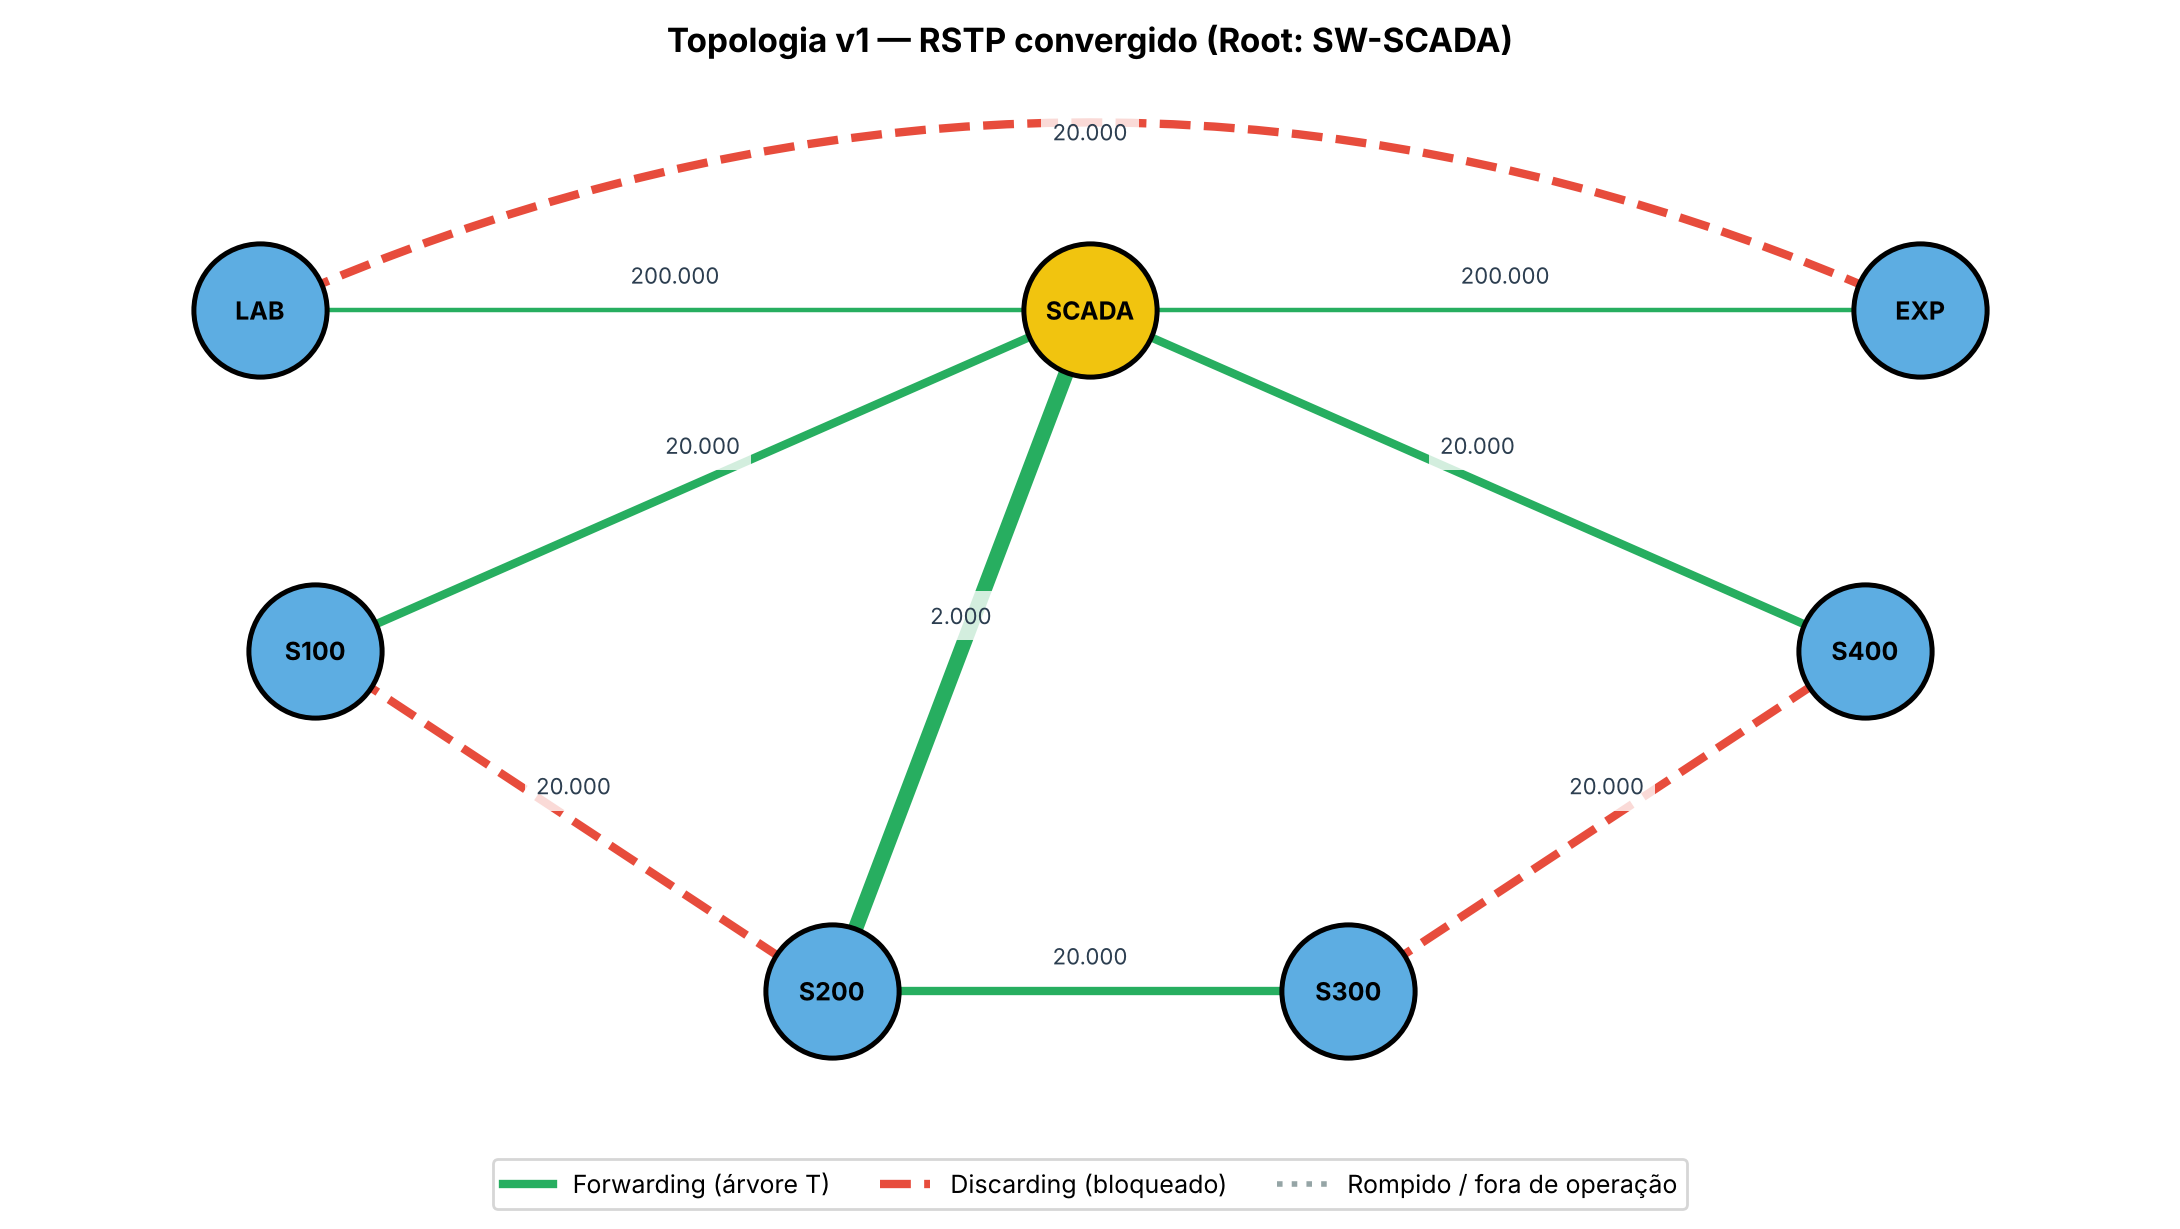

In [3]:
POS = {
    "SW-SCADA": (0.50, 0.88), "SW-LAB": (0.05, 0.88), "SW-EXP": (0.95, 0.88),
    "SW-S100": (0.08, 0.50), "SW-S200": (0.36, 0.12), "SW-S300": (0.64, 0.12), "SW-S400": (0.92, 0.50),
}
LARGURA = {CUSTO_10G: 5.5, CUSTO_1G: 3.0, CUSTO_100M: 1.6}

def plotar(rede, res, titulo, rompidos=(), mortos=(), ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(11, 6.2))
    raizes = {r["raiz"] for r in res}
    ativas = {frozenset(e) for r in res for e in r["ativas"]}
    def tracado(u, v):
        # Enlaces que passariam por cima de outro switch são desenhados em arco.
        (x1, y1), (x2, y2) = POS[u], POS[v]
        if {u, v} == {"SW-LAB", "SW-EXP"}:
            ts = [i / 40 for i in range(41)]
            xs = [(1 - t) ** 2 * x1 + 2 * t * (1 - t) * 0.5 + t ** 2 * x2 for t in ts]
            ys = [(1 - t) ** 2 * y1 + 2 * t * (1 - t) * 1.30 + t ** 2 * y2 for t in ts]
            return xs, ys, (0.5, 1.07)
        return [x1, x2], [y1, y2], ((x1 + x2) / 2, (y1 + y2) / 2 + 0.03)
    for u, v, c, _ in rede.enlaces:
        xs, ys, (lx, ly) = tracado(u, v)
        if frozenset((u, v)) in ativas:
            ax.plot(xs, ys, color="#27AE60", lw=LARGURA[c], zorder=1)
        else:
            ax.plot(xs, ys, color="#E74C3C", lw=LARGURA[c], ls="--", zorder=1)
        ax.text(lx, ly, f"{c:,}".replace(",", "."), fontsize=8,
                ha="center", color="#2C3E50", bbox=dict(fc="white", ec="none", alpha=0.8))
    for u, v in rompidos:
        xs, ys, (lx, ly) = tracado(u, v)
        ax.plot(xs, ys, color="#95A5A6", lw=2, ls=":", zorder=0)
        ax.text(lx, ly - 0.08, "ROMPIDO", fontsize=8, ha="center", color="#7F8C8D")
    for x, (px, py) in POS.items():
        if x in mortos:
            cor = "#BDC3C7"
        elif x in raizes:
            cor = "#F1C40F"
        else:
            cor = "#5DADE2"
        ax.scatter(px, py, s=2300, c=cor, edgecolors="black", linewidths=1.8, zorder=2)
        ax.text(px, py, x.replace("SW-", ""), ha="center", va="center", fontsize=9, fontweight="bold", zorder=3)
    leg = [Line2D([0], [0], color="#27AE60", lw=3, label="Forwarding (árvore T)"),
           Line2D([0], [0], color="#E74C3C", lw=3, ls="--", label="Discarding (bloqueado)"),
           Line2D([0], [0], color="#95A5A6", lw=2, ls=":", label="Rompido / fora de operação")]
    ax.legend(handles=leg, loc="lower center", bbox_to_anchor=(0.5, -0.1), ncol=3, fontsize=9)
    ax.set_title(titulo, fontsize=12, fontweight="bold")
    ax.set_xlim(-0.08, 1.08); ax.set_ylim(-0.02, 1.15); ax.axis("off")
    return ax

plotar(rede_v1, res_v1, "Topologia v1 — RSTP convergido (Root: SW-SCADA)")
plt.tight_layout(); plt.show()

### 4. RSTP não é Kruskal/Prim: SPT × MST

Um erro comum é dizer que o STP "calcula a Árvore Geradora Mínima". Não calcula. O RSTP constrói a **árvore de caminhos mínimos até a raiz** (*Shortest-Path Tree*, SPT): cada switch escolhe, de forma distribuída, o caminho mais barato **até o Root Bridge**. Já Kruskal e Prim (Aula 19) minimizam a **soma total** dos pesos da árvore, sem olhar para nenhuma raiz.

As duas árvores coincidem em muitas redes, mas não em todas. A topologia v1 da fábrica de paçoca é um contraexemplo: abaixo, Kruskal com *Union-Find* é executado sobre o mesmo grafo e comparado com a árvore do RSTP.

In [4]:
class UnionFind:
    def __init__(self, elementos):
        self.pai = {e: e for e in elementos}
    def achar(self, x):
        while self.pai[x] != x:
            self.pai[x] = self.pai[self.pai[x]]
            x = self.pai[x]
        return x
    def unir(self, a, b):
        ra, rb = self.achar(a), self.achar(b)
        if ra == rb:
            return False
        self.pai[rb] = ra
        return True

def kruskal(rede):
    uf = UnionFind(rede.nos)
    arvore = []
    for u, v, c, _ in sorted(rede.enlaces, key=lambda e: e[2]):  # ordenação estável
        if uf.unir(u, v):
            arvore.append((u, v))
    return arvore

def custo_ate_raiz_na_arvore(rede, arestas, raiz):
    adj = {x: [] for x in rede.nos}
    for u, v in arestas:
        adj[u].append(v); adj[v].append(u)
    dist, pilha = {raiz: 0}, [raiz]
    while pilha:
        x = pilha.pop()
        for y in adj[x]:
            if y not in dist:
                dist[y] = dist[x] + rede.custo(x, y)
                pilha.append(y)
    return dist

raiz = res_v1[0]["raiz"]
spt = res_v1[0]["ativas"]
mst = kruskal(rede_v1)
peso = lambda arestas: sum(rede_v1.custo(u, v) for u, v in arestas)
d_spt = custo_ate_raiz_na_arvore(rede_v1, spt, raiz)
d_mst = custo_ate_raiz_na_arvore(rede_v1, mst, raiz)

comparacao = pd.DataFrame([
    {"Switch": x, "Custo até a raiz na SPT (RSTP)": d_spt[x], "Custo até a raiz na MST (Kruskal)": d_mst[x],
     "Penalidade da MST": d_mst[x] - d_spt[x]} for x in sorted(rede_v1.nos, key=lambda k: d_spt[k])])
display(comparacao)

so_spt = {frozenset(e) for e in spt} - {frozenset(e) for e in mst}
so_mst = {frozenset(e) for e in mst} - {frozenset(e) for e in spt}
print(f"Peso total da SPT (RSTP):    {peso(spt):>9,}")
print(f"Peso total da MST (Kruskal): {peso(mst):>9,}")
print("Enlaces só na SPT:", [" <-> ".join(sorted(e)) for e in so_spt])
print("Enlaces só na MST:", [" <-> ".join(sorted(e)) for e in so_mst])

,Switch,Custo até a raiz na SPT (RSTP),Custo até a raiz na MST (Kruskal),Penalidade da MST
0,SW-SCADA,0,0,0
1,SW-S200,2000,2000,0
2,SW-S100,20000,20000,0
3,SW-S400,20000,42000,22000
4,SW-S300,22000,22000,0
5,SW-LAB,200000,200000,0
6,SW-EXP,200000,220000,20000


Peso total da SPT (RSTP):      462,000
Peso total da MST (Kruskal):   282,000
Enlaces só na SPT: ['SW-S400 <-> SW-SCADA', 'SW-EXP <-> SW-SCADA']
Enlaces só na MST: ['SW-EXP <-> SW-LAB', 'SW-S300 <-> SW-S400']


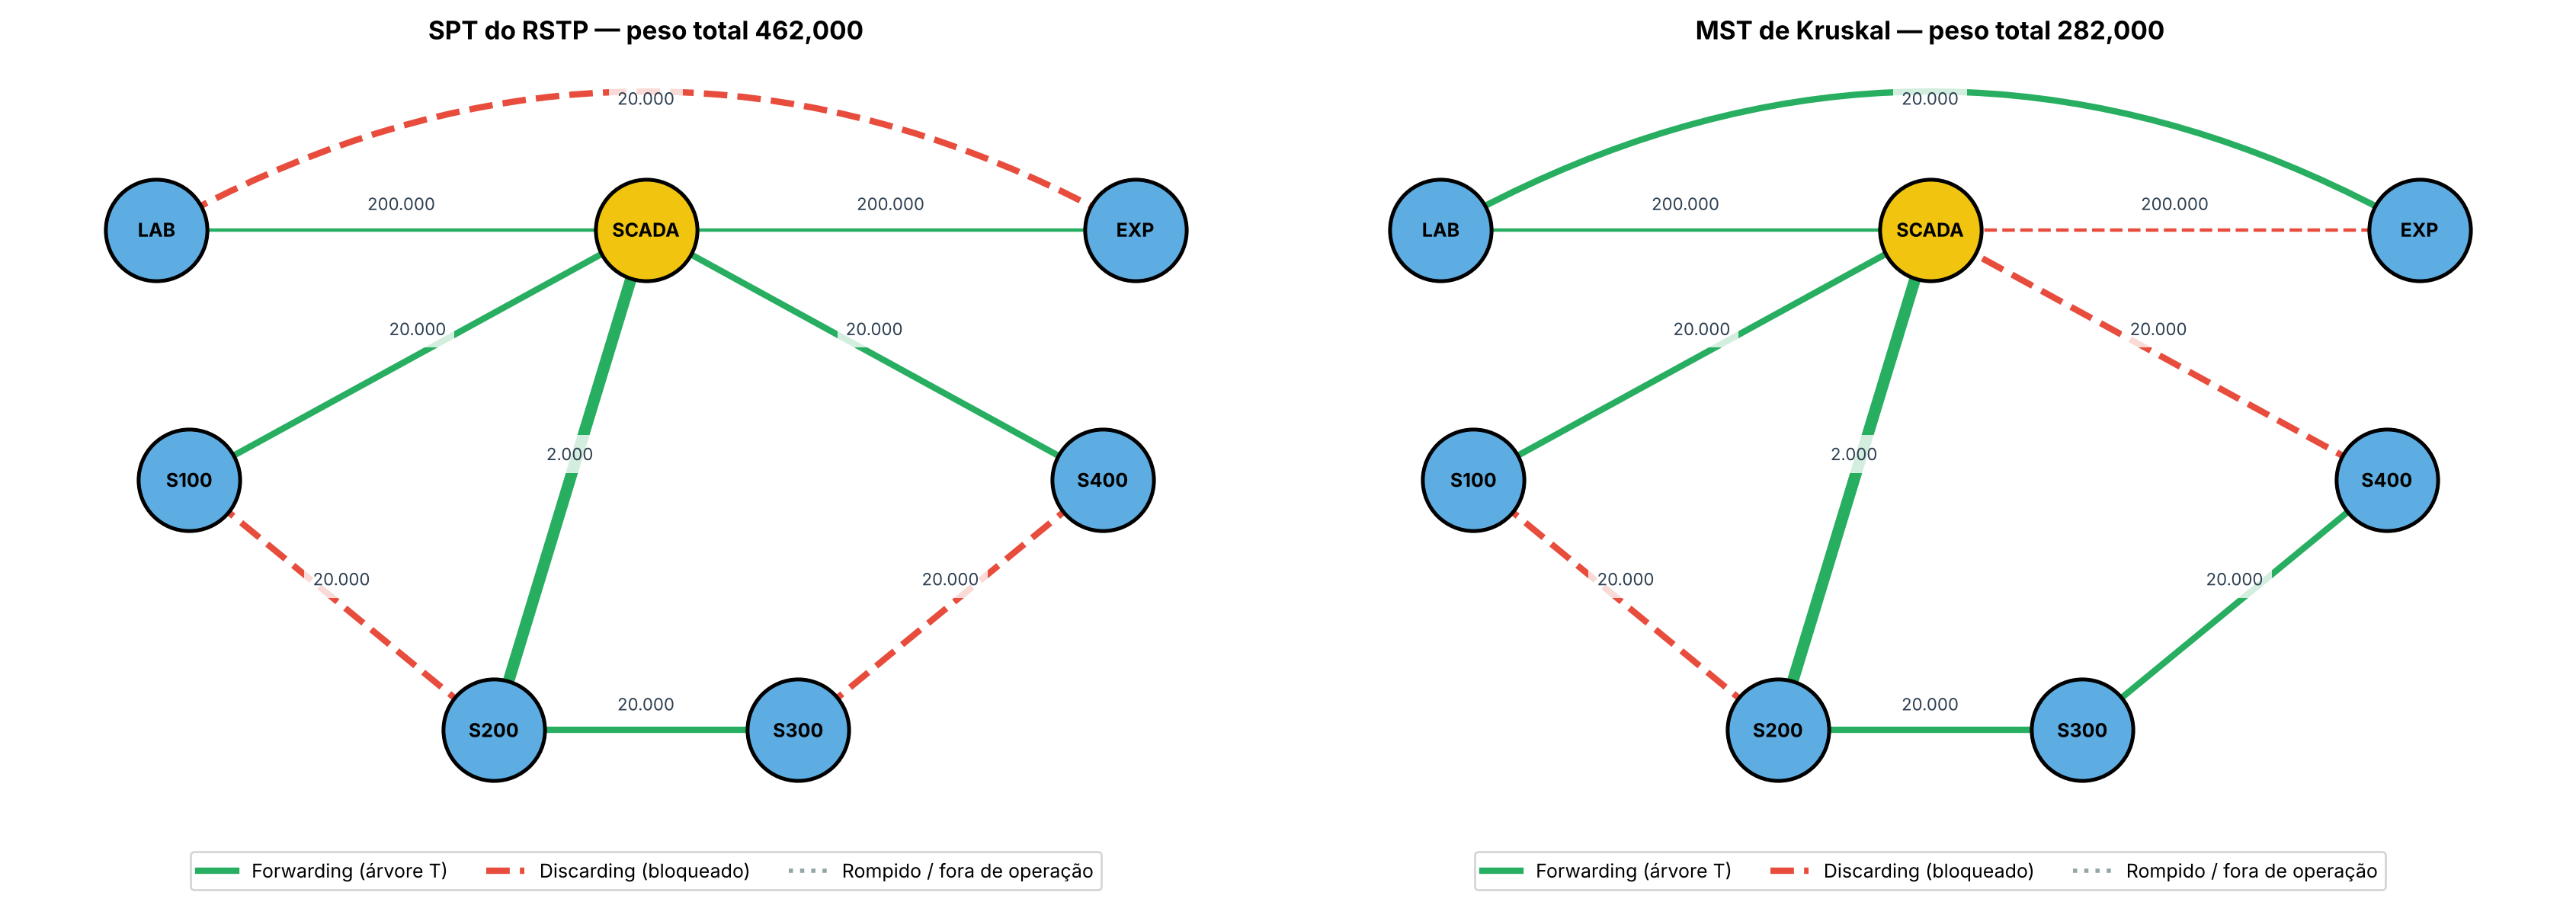

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(17, 6))
plotar(rede_v1, res_v1, f"SPT do RSTP — peso total {peso(spt):,}", ax=axs[0])
res_mst = [{"raiz": raiz, "ativas": mst}]
plotar(rede_v1, res_mst, f"MST de Kruskal — peso total {peso(mst):,}", ax=axs[1])
plt.tight_layout(); plt.show()

**Leitura de engenharia.** A MST "economiza" peso total ligando o Galpão B ao Lab pela fibra e usando um único cobre legado, mas, com isso, o tráfego do WMS da expedição passaria por dois saltos até a Sala de Controle. A MST também pode trocar o enlace direto `SW-S400 ↔ SW-SCADA` pelo caminho através da moagem, alongando o caminho dos dados do CLP 04 (detector de metais `MD-401`, visão `VS-401`). Como quase todo o tráfego supervisório converge para os servidores SCADA, o critério do RSTP (minimizar o custo **de cada switch até a raiz**) é o correto para a rede, e não o critério da MST.

Por outro lado, a SPT revela um ponto fraco do projeto v1: o Lab e a Expedição falam com a Sala de Controle por **cobre de 100 Mbps**, enquanto a fibra de 1 Gbps entre eles fica bloqueada — o caminho alternativo soma $200.000 + 20.000 = 220.000 > 200.000$. O RSTP está seguindo a norma corretamente; quem precisa ser revisto é o projeto físico (Seção 6).

### 5. Falha 1 — Rompimento do Backbone de 10 Gbps `SW-SCADA ↔ SW-S200`

O enlace mais crítico da planta liga a Sala de Controle ao setor do forno de torra. Simulamos o seu rompimento (ex.: dano mecânico no eletroduto durante manutenção do queimador) e verificamos para quais portas o RSTP transfere o tráfego. O interesse está nas **Alternate Ports**: no RSTP, uma porta *Alternate* que já recebia BPDUs com caminho válido para a raiz assume o papel de *Root Port* sem esperar temporizadores.

Componentes conexos após a falha: 1
  SW-SCADA  Root Path Cost:       0 ->       0
  SW-S100   Root Path Cost:  20,000 ->  20,000
  SW-S400   Root Path Cost:  20,000 ->  20,000
  SW-S200   Root Path Cost:   2,000 ->  40,000  <-- mudou
  SW-S300   Root Path Cost:  22,000 ->  40,000  <-- mudou
  SW-LAB    Root Path Cost: 200,000 -> 200,000
  SW-EXP    Root Path Cost: 200,000 -> 200,000

Portas que mudaram de papel:


,Switch,Porta para,Antes,Depois
0,SW-S100,SW-S200,AP,DP
1,SW-S200,SW-S100,DP,RP
2,SW-S200,SW-SCADA,RP,ROMPIDA
3,SW-S300,SW-S200,RP,AP
4,SW-S300,SW-S400,AP,RP
5,SW-SCADA,SW-S200,DP,ROMPIDA


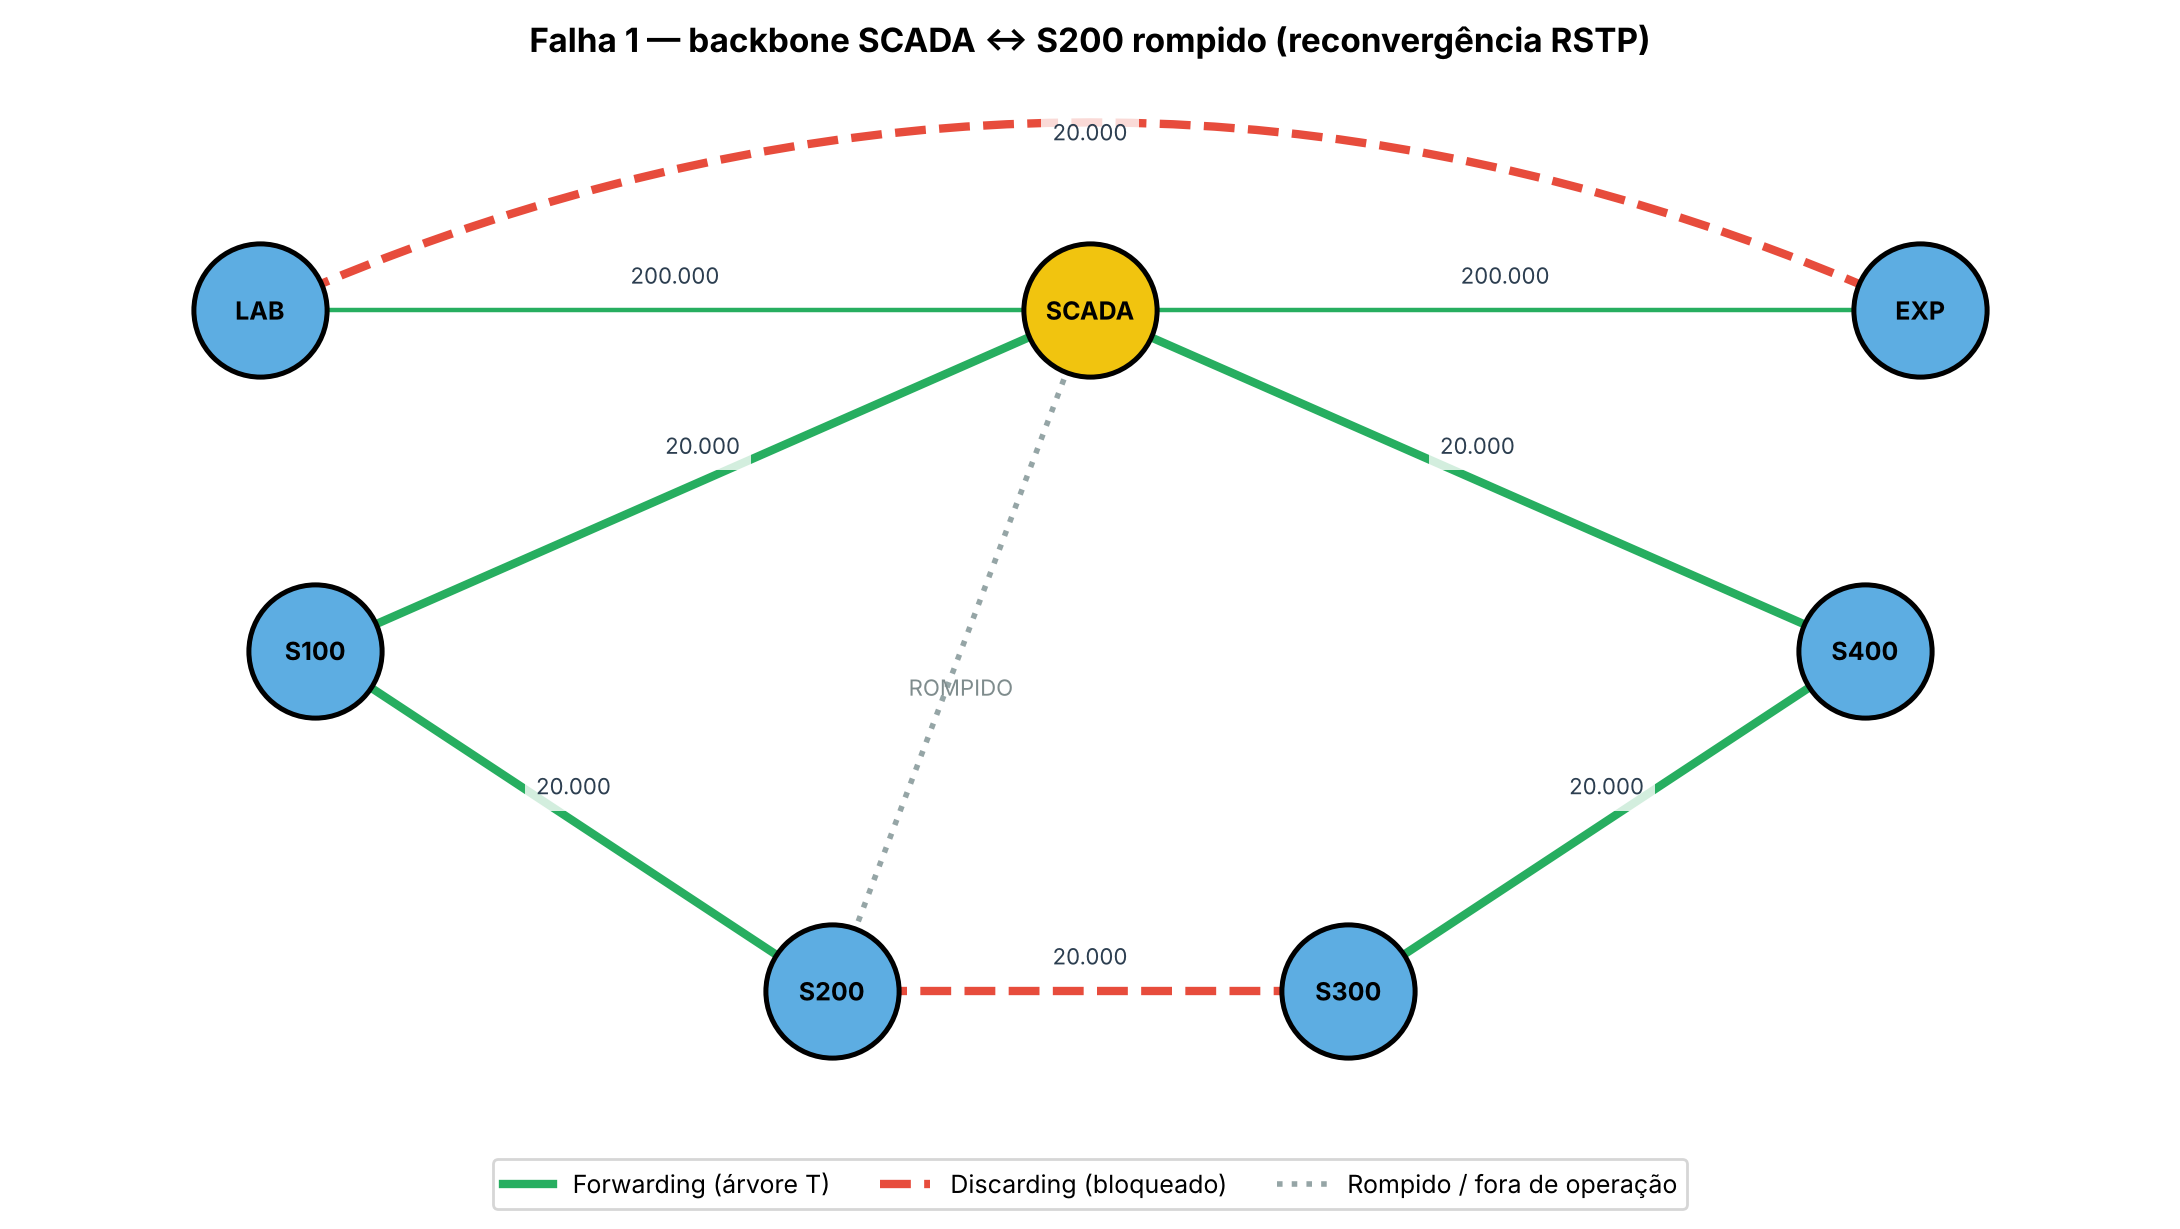

In [6]:
def papeis_por_switch(rede, res):
    # Dicionário {(switch, vizinho): papel} para comparar antes/depois de uma falha.
    papeis = {}
    for r in res:
        for u, v, c, _ in rede.enlaces:
            if u not in r["componente"]:
                continue
            if r["pai"].get(v) == u:
                papeis[(u, v)], papeis[(v, u)] = "DP", "RP"
            elif r["pai"].get(u) == v:
                papeis[(u, v)], papeis[(v, u)] = "RP", "DP"
            else:
                desig = min((u, v), key=lambda x: (r["dist"][x], rede.bid(x)))
                alt = v if desig == u else u
                papeis[(desig, alt)], papeis[(alt, desig)] = "DP", "AP"
    return papeis

def comparar_transicoes(rede_antes, res_antes, rede_depois, res_depois):
    pa, pd_ = papeis_por_switch(rede_antes, res_antes), papeis_por_switch(rede_depois, res_depois)
    linhas = []
    for porta in sorted(set(pa) | set(pd_)):
        a, d = pa.get(porta, "—"), pd_.get(porta, "ROMPIDA")
        if a != d:
            linhas.append({"Switch": porta[0], "Porta para": porta[1], "Antes": a, "Depois": d})
    return pd.DataFrame(linhas)

falha1 = ("SW-SCADA", "SW-S200")
rede_f1 = rede_v1.sem_enlace(*falha1)
res_f1 = executar_rstp(rede_f1)

print(f"Componentes conexos após a falha: {len(res_f1)}")
custos_f1 = res_f1[0]["dist"]
for x in sorted(rede_v1.nos, key=lambda k: custos_f1[k]):
    antes = res_v1[0]["dist"][x]
    marca = "  <-- mudou" if custos_f1[x] != antes else ""
    print(f"  {x:9s} Root Path Cost: {antes:>7,} -> {custos_f1[x]:>7,}{marca}")

print("\nPortas que mudaram de papel:")
display(comparar_transicoes(rede_v1, res_v1, rede_f1, res_f1))
plotar(rede_f1, res_f1, "Falha 1 — backbone SCADA <-> S200 rompido (reconvergência RSTP)", rompidos=[falha1])
plt.tight_layout(); plt.show()

**Interpretação.** O switch do forno (`SW-S200`) perde a sua *Root Port* e, como as outras portas dele eram *Designated*, ele não tem uma *Alternate* própria. Ele passa a anunciar BPDUs inferiores; o `SW-S100`, cuja porta para o S200 estava em *Alternate*, reconhece que conhece um caminho melhor até a raiz e torna essa porta *Designated* via mecanismo *Proposal/Agreement*. Em paralelo, o `SW-S300` promove a sua *Alternate Port* (para o S400) a *Root Port*, e a porta dele voltada ao S200 passa a *Alternate* (empate de custo 40.000 resolvido pelo menor BID, que é o do S200). Resultado: o anel de 1 Gbps passa a carregar o tráfego do forno, com custo 40.000 em vez de 2.000, e a telemetria de `TT-201`, `TS-201` e `FS-201` continua chegando ao SCADA.

### 6. Falha 2 — Perda do Root Bridge e Pontos de Articulação

Agora o próprio `SW-SCADA` falha (ex.: queima da fonte do rack). O `SW-S200` (prioridade 8192) deve assumir como raiz secundária. Mas há uma pergunta de teoria dos grafos antes: **a rede continua conexa sem o `SW-SCADA`?**

Um vértice cuja remoção desconecta o grafo é um **ponto de articulação** (*cut vertex*). Implementamos o algoritmo de Tarjan (DFS com tempos de descoberta e *low-link*, $O(|V| + |E|)$) para encontrar esses pontos e também as **pontes** (*bridges*, arestas de corte).

In [7]:
def articulacoes_e_pontes(rede):
    tempo = [0]
    desc, low, pai = {}, {}, {}
    articulacoes, pontes = set(), []

    def dfs(u):
        desc[u] = low[u] = tempo[0]; tempo[0] += 1
        filhos = 0
        for v in rede.adj[u]:
            if v not in desc:
                pai[v] = u
                filhos += 1
                dfs(v)
                low[u] = min(low[u], low[v])
                if pai.get(u) is None and filhos > 1:
                    articulacoes.add(u)
                if pai.get(u) is not None and low[v] >= desc[u]:
                    articulacoes.add(u)
                if low[v] > desc[u]:
                    pontes.append((u, v))
            elif v != pai.get(u):
                low[u] = min(low[u], desc[v])

    for s in rede.nos:
        if s not in desc:
            pai[s] = None
            dfs(s)
    return articulacoes, pontes

art_v1, pontes_v1 = articulacoes_e_pontes(rede_v1)
print("Topologia v1")
print("  Pontos de articulação:", sorted(art_v1) if art_v1 else "nenhum")
print("  Pontes (enlaces de corte):", pontes_v1 if pontes_v1 else "nenhuma")

Topologia v1
  Pontos de articulação: ['SW-SCADA']
  Pontes (enlaces de corte): nenhuma


Após a perda do SW-SCADA a rede ficou com 2 ilha(s):
  Ilha ['SW-EXP', 'SW-LAB'] -> Root Bridge eleito: SW-LAB
  Ilha ['SW-S100', 'SW-S200', 'SW-S300', 'SW-S400'] -> Root Bridge eleito: SW-S200


,Switch,Local,Raiz da ilha,Root Path Cost,Root Port
0,SW-LAB,Laboratório de Qualidade + AP do AGV,SW-LAB,0,—
1,SW-EXP,Galpão B - Expedição/WMS,SW-LAB,20000,porta para SW-LAB
2,SW-S200,Setor 200 - Torra/Despel. (CLP 02),SW-S200,0,—
3,SW-S300,Setor 300 - Dosagem/Moagem (CLP 03),SW-S200,20000,porta para SW-S200
4,SW-S100,Setor 100 - Recepção/Limpeza (CLP 01),SW-S200,20000,porta para SW-S200
5,SW-S400,Setor 400 - Prensa/Embalagem (CLP 04),SW-S200,40000,porta para SW-S300


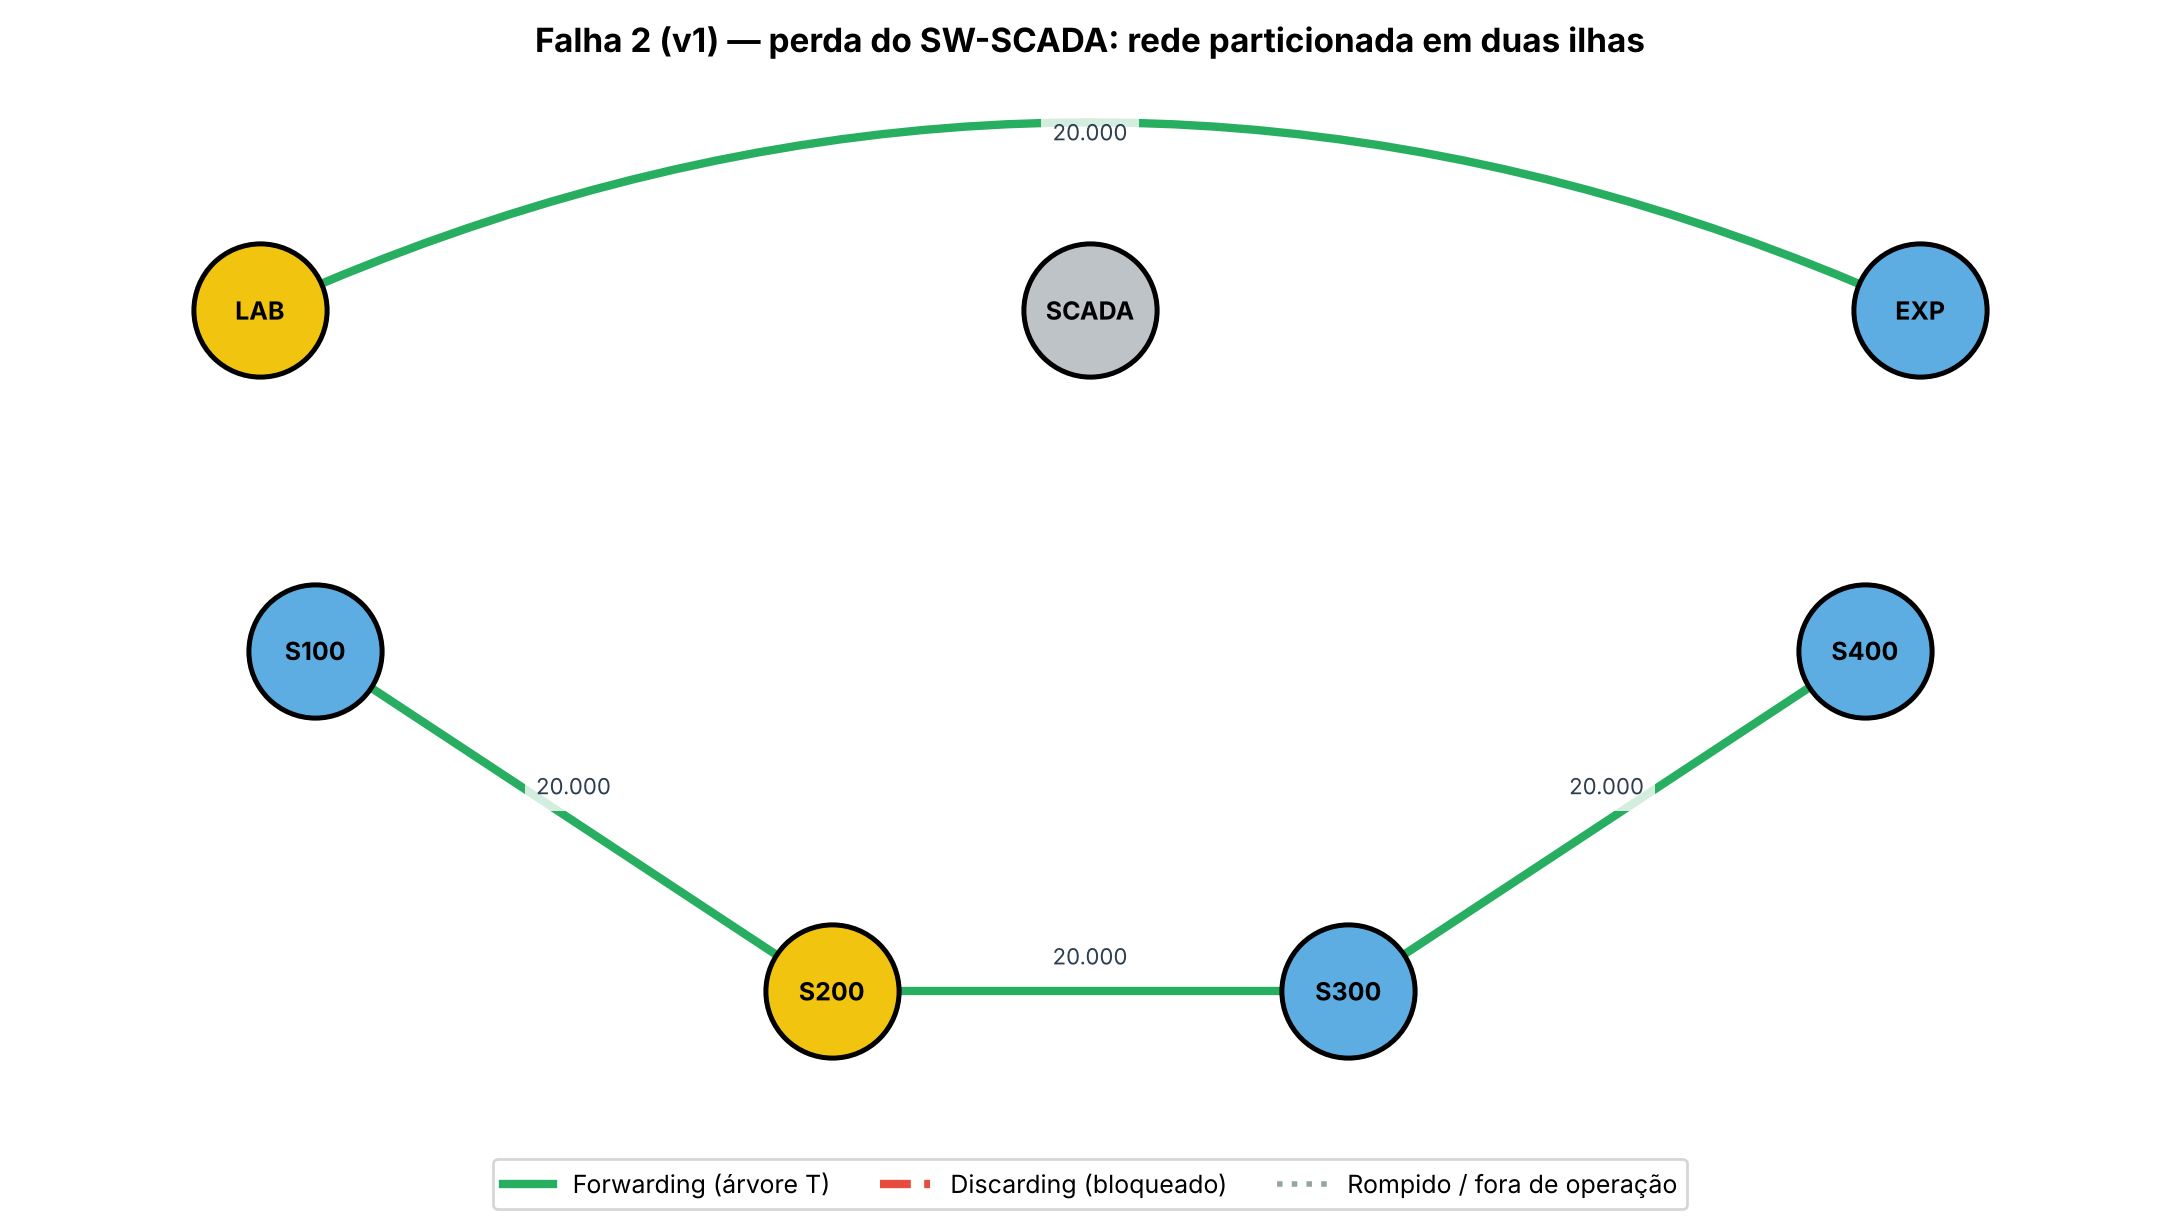

In [8]:
rede_f2 = rede_v1.sem_switch("SW-SCADA")
res_f2 = executar_rstp(rede_f2)

print(f"Após a perda do SW-SCADA a rede ficou com {len(res_f2)} ilha(s):")
for r in res_f2:
    print(f"  Ilha {sorted(r['componente'])} -> Root Bridge eleito: {r['raiz']}")
display(resumo_custos(rede_f2, res_f2))
plotar(rede_f2, res_f2, "Falha 2 (v1) — perda do SW-SCADA: rede particionada em duas ilhas", mortos=["SW-SCADA"])
plt.tight_layout(); plt.show()

**Consequência na fábrica de paçoca.** O núcleo fabril (S100–S400) continua íntegro e elege o `SW-S200` como nova raiz, como planejado. Porém o Laboratório e o Galpão B formam uma **ilha isolada**: o CLP 04 não consegue informar ao WMS da expedição que um palete foi bloqueado por contaminação metálica (`MD-401`, `POP-SEG-01` da Aula 10), e o Lab não consegue publicar a liberação de lotes. É um risco de **expedir produto não conforme** — falha de rastreabilidade HACCP — causado por um único equipamento. O RSTP não resolve isso: nenhum protocolo de camada 2 cria um caminho que não existe fisicamente.

### 7. Correção de Projeto — Topologia v2

Correção proposta: lançar uma fibra de 1 Gbps entre `SW-S400` (prensa/embalagem) e `SW-EXP` (Galpão B), acompanhando o próprio fluxo físico do produto (embalagem → paletização → expedição). Isso deve:
1. eliminar o ponto de articulação `SW-SCADA`;
2. tirar o Lab e a Expedição do cobre legado em operação normal, deixando os enlaces de 100 Mbps como reserva.

Topologia v2: |V| = 7, |E| = 10, ciclos independentes = 4
  Pontos de articulação: nenhum (grafo 2-vértice-conexo)
  Pontes: nenhuma (grafo 2-aresta-conexo)



,Switch,Local,Raiz da ilha,Root Path Cost,Root Port
0,SW-SCADA,Sala de Controle (SCADA/Historiador),SW-SCADA,0,—
1,SW-S200,Setor 200 - Torra/Despel. (CLP 02),SW-SCADA,2000,porta para SW-SCADA
2,SW-S100,Setor 100 - Recepção/Limpeza (CLP 01),SW-SCADA,20000,porta para SW-SCADA
3,SW-S400,Setor 400 - Prensa/Embalagem (CLP 04),SW-SCADA,20000,porta para SW-SCADA
4,SW-S300,Setor 300 - Dosagem/Moagem (CLP 03),SW-SCADA,22000,porta para SW-S200
5,SW-EXP,Galpão B - Expedição/WMS,SW-SCADA,40000,porta para SW-S400
6,SW-LAB,Laboratório de Qualidade + AP do AGV,SW-SCADA,60000,porta para SW-EXP


,Enlace,Custo,Porta em u,Porta em v,Status
0,SW-SCADA <-> SW-S200,2000,SW-SCADA: DP [Forwarding],SW-S200: RP [Forwarding],ATIVO (árvore T)
1,SW-SCADA <-> SW-S100,20000,SW-SCADA: DP [Forwarding],SW-S100: RP [Forwarding],ATIVO (árvore T)
2,SW-S100 <-> SW-S200,20000,SW-S100: AP [Discarding],SW-S200: DP [Forwarding],BLOQUEADO (AP em SW-S100)
3,SW-S200 <-> SW-S300,20000,SW-S200: DP [Forwarding],SW-S300: RP [Forwarding],ATIVO (árvore T)
4,SW-S300 <-> SW-S400,20000,SW-S300: AP [Discarding],SW-S400: DP [Forwarding],BLOQUEADO (AP em SW-S300)
5,SW-S400 <-> SW-SCADA,20000,SW-S400: RP [Forwarding],SW-SCADA: DP [Forwarding],ATIVO (árvore T)
6,SW-SCADA <-> SW-LAB,200000,SW-SCADA: DP [Forwarding],SW-LAB: AP [Discarding],BLOQUEADO (AP em SW-LAB)
7,SW-SCADA <-> SW-EXP,200000,SW-SCADA: DP [Forwarding],SW-EXP: AP [Discarding],BLOQUEADO (AP em SW-EXP)
8,SW-LAB <-> SW-EXP,20000,SW-LAB: RP [Forwarding],SW-EXP: DP [Forwarding],ATIVO (árvore T)
9,SW-S400 <-> SW-EXP,20000,SW-S400: DP [Forwarding],SW-EXP: RP [Forwarding],ATIVO (árvore T)


Peso da SPT v2 = 102,000 | Peso da MST v2 = 102,000


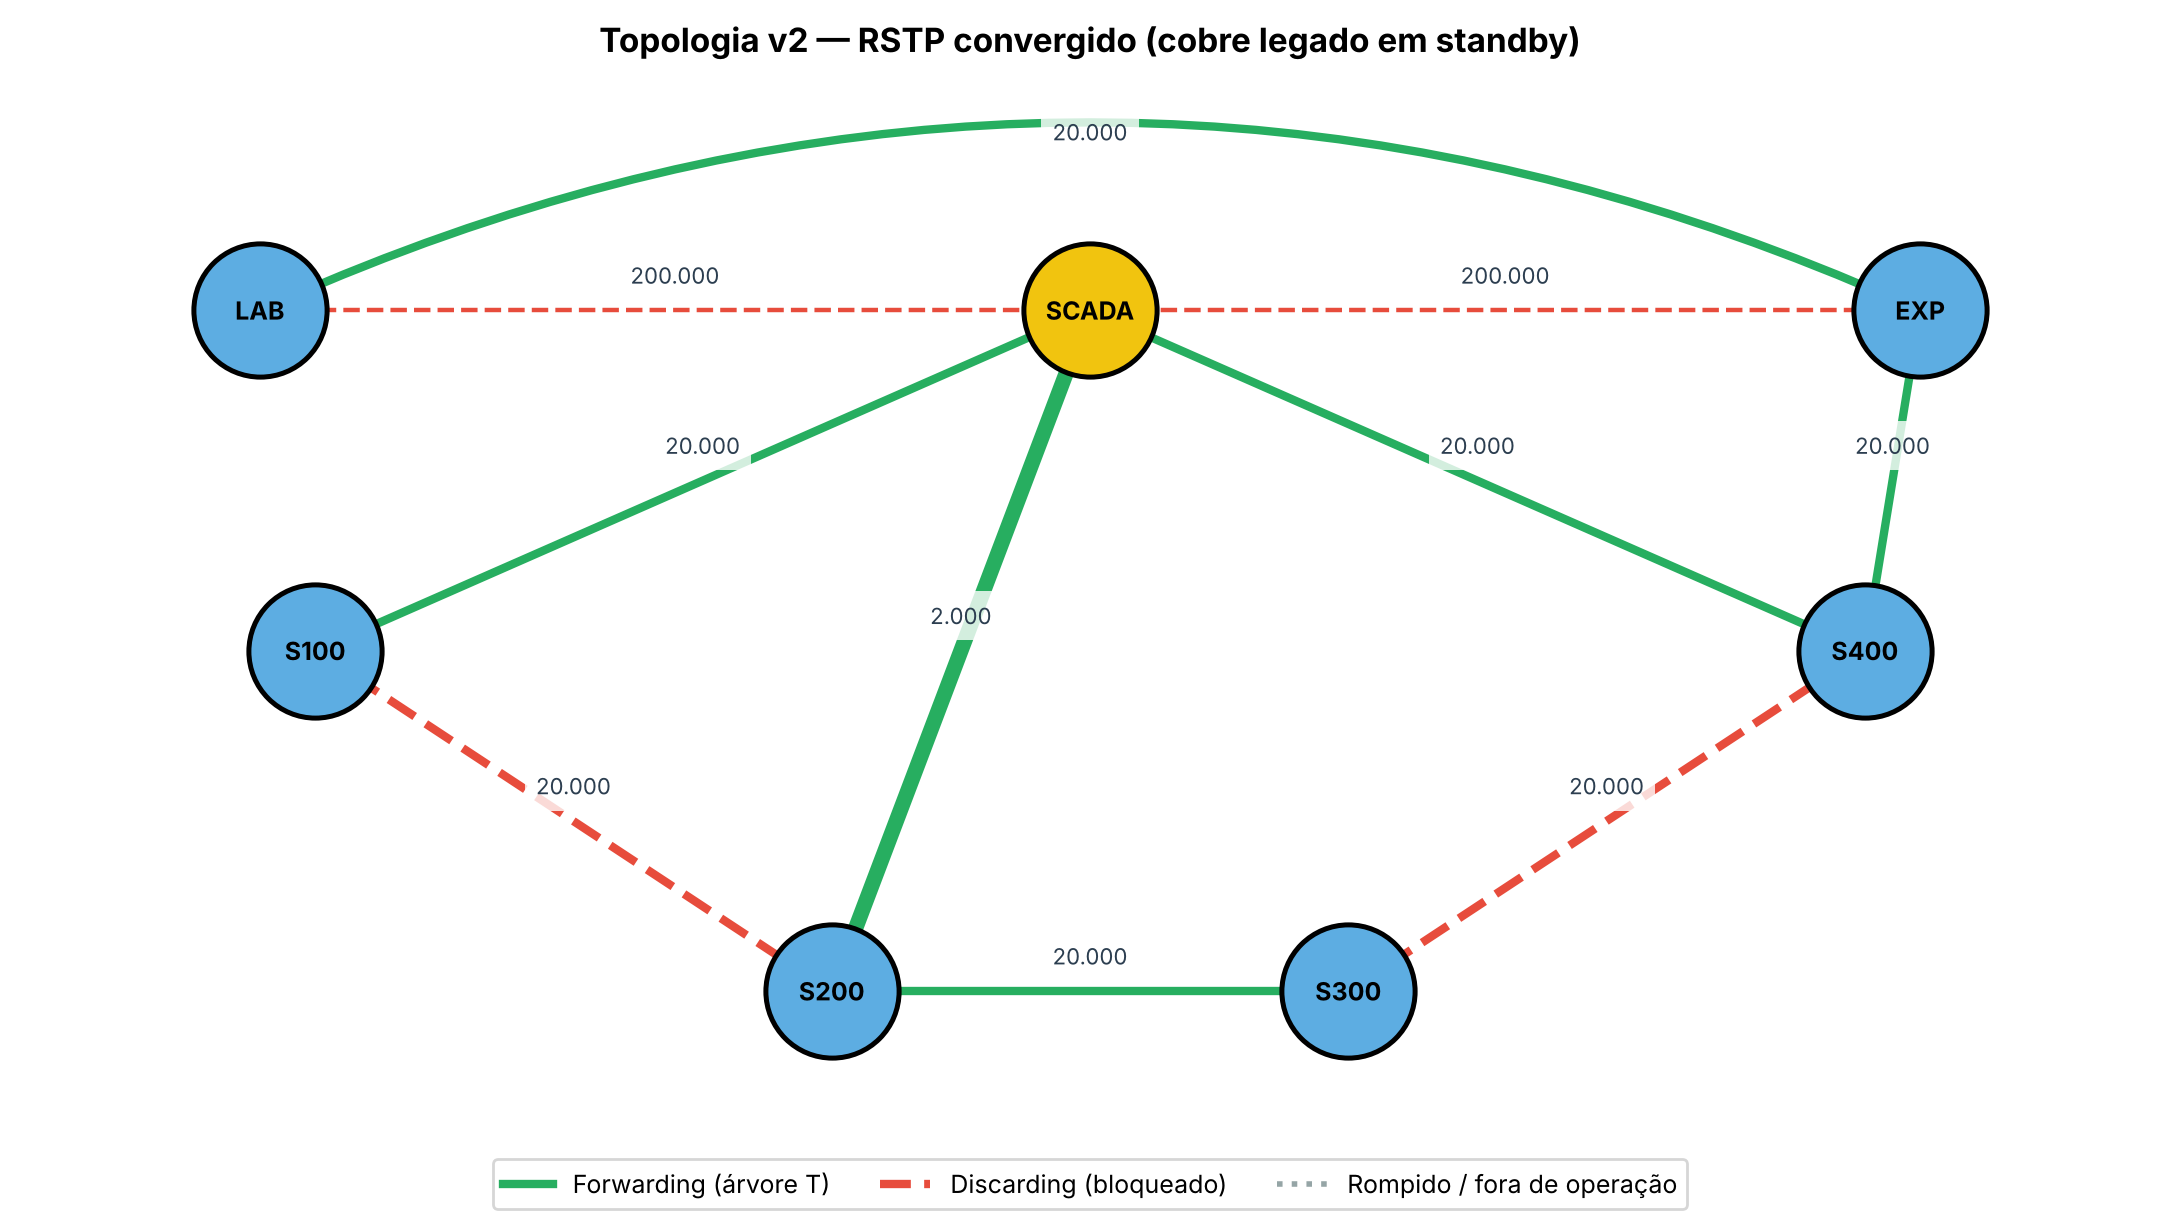

In [9]:
rede_v2 = rede_v1.com_enlace("SW-S400", "SW-EXP", CUSTO_1G, "1 Gbps fibra - embalagem -> Galpão B (NOVO)")
res_v2 = executar_rstp(rede_v2)
art_v2, pontes_v2 = articulacoes_e_pontes(rede_v2)

n2, m2 = len(rede_v2.nos), len(rede_v2.enlaces)
print(f"Topologia v2: |V| = {n2}, |E| = {m2}, ciclos independentes = {m2 - n2 + 1}")
print("  Pontos de articulação:", sorted(art_v2) if art_v2 else "nenhum (grafo 2-vértice-conexo)")
print("  Pontes:", pontes_v2 if pontes_v2 else "nenhuma (grafo 2-aresta-conexo)\n")
display(resumo_custos(rede_v2, res_v2))
display(res_v2[0]["tabela"])
print(f"Peso da SPT v2 = {sum(rede_v2.custo(u, v) for u, v in res_v2[0]['ativas']):,} | "
      f"Peso da MST v2 = {sum(rede_v2.custo(u, v) for u, v in kruskal(rede_v2)):,}")
plotar(rede_v2, res_v2, "Topologia v2 — RSTP convergido (cobre legado em standby)")
plt.tight_layout(); plt.show()

v2 sem o SW-SCADA: 1 ilha(s); raiz eleita: SW-S200


,Switch,Local,Raiz da ilha,Root Path Cost,Root Port
0,SW-S200,Setor 200 - Torra/Despel. (CLP 02),SW-S200,0,—
1,SW-S100,Setor 100 - Recepção/Limpeza (CLP 01),SW-S200,20000,porta para SW-S200
2,SW-S300,Setor 300 - Dosagem/Moagem (CLP 03),SW-S200,20000,porta para SW-S200
3,SW-S400,Setor 400 - Prensa/Embalagem (CLP 04),SW-S200,40000,porta para SW-S300
4,SW-EXP,Galpão B - Expedição/WMS,SW-S200,60000,porta para SW-S400
5,SW-LAB,Laboratório de Qualidade + AP do AGV,SW-S200,80000,porta para SW-EXP


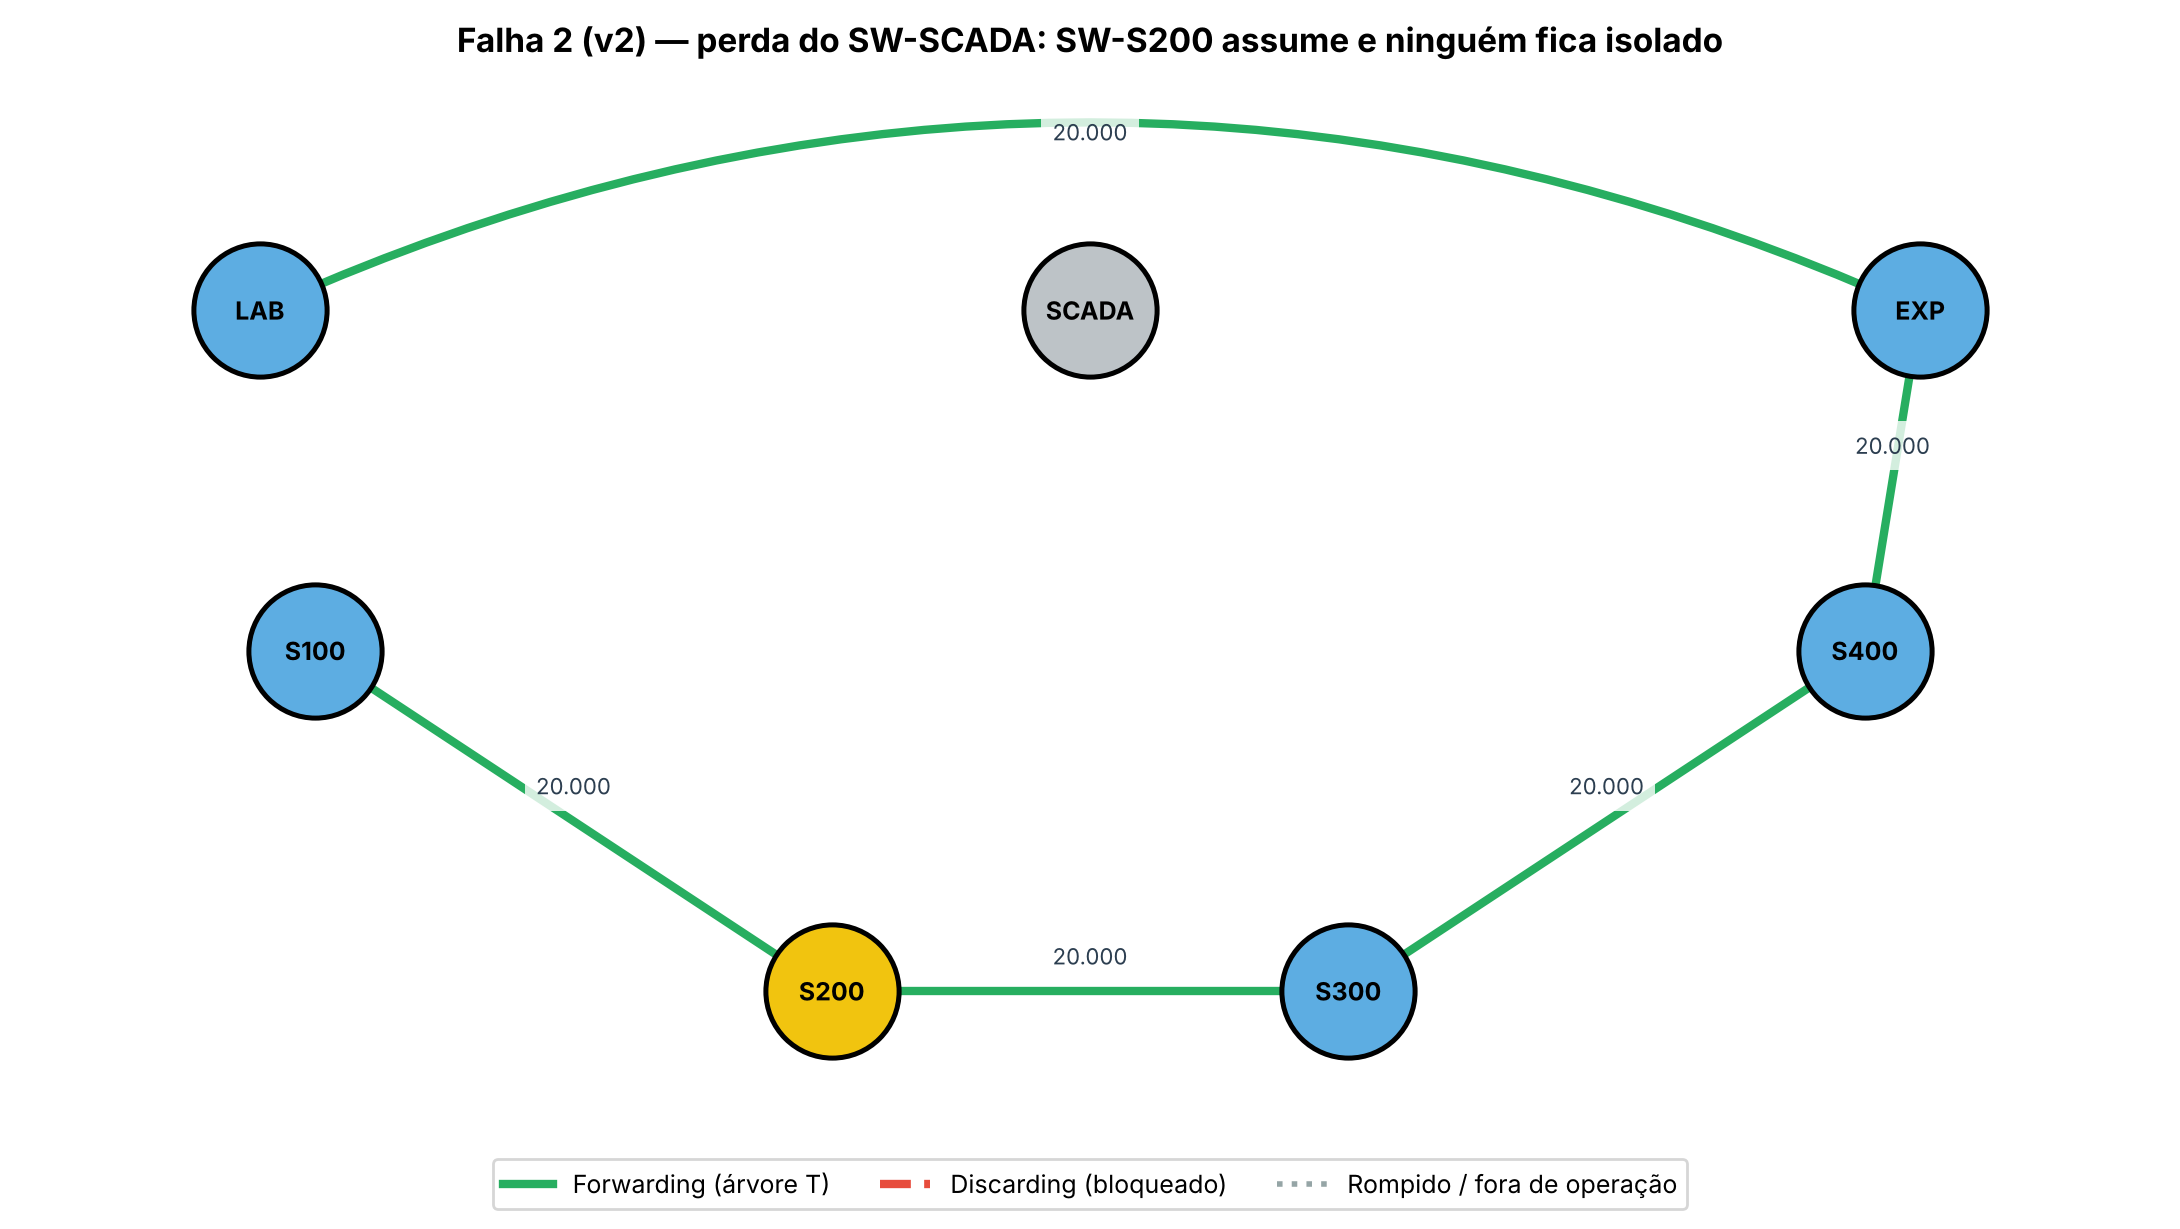

In [10]:
rede_v2_f2 = rede_v2.sem_switch("SW-SCADA")
res_v2_f2 = executar_rstp(rede_v2_f2)
print(f"v2 sem o SW-SCADA: {len(res_v2_f2)} ilha(s); raiz eleita: {res_v2_f2[0]['raiz']}")
display(resumo_custos(rede_v2_f2, res_v2_f2))
plotar(rede_v2_f2, res_v2_f2, "Falha 2 (v2) — perda do SW-SCADA: SW-S200 assume e ninguém fica isolado",
       mortos=["SW-SCADA"])
plt.tight_layout(); plt.show()

### 8. Teste de Contingência N-1 e Auditoria Formal da Árvore

Para cada cenário de **falha simples** (cada enlace rompido isoladamente e cada switch perdido isoladamente) verificamos, nas topologias v1 e v2:
1. se todos os switches sobreviventes continuam numa única ilha;
2. se o subgrafo lógico de cada ilha é uma **árvore geradora**: $|E_T| = |V_T| - 1$, conexo e acíclico (verificação independente por *Union-Find*).

In [11]:
def e_arvore_geradora(nos, arestas):
    # Conexo + acíclico <=> |E| = |V| - 1 e nenhuma aresta fecha ciclo.
    uf = UnionFind(nos)
    for u, v in arestas:
        if not uf.unir(u, v):
            return False  # fechou ciclo -> tempestade de broadcast
    return len(arestas) == len(nos) - 1

def teste_n_menos_1(rede, nome):
    cenarios = [("enlace", (u, v)) for u, v, _, _ in rede.enlaces] + [("switch", x) for x in rede.nos]
    linhas = []
    for tipo, alvo in cenarios:
        r_fail = rede.sem_enlace(*alvo) if tipo == "enlace" else rede.sem_switch(alvo)
        res = executar_rstp(r_fail)
        arvores_ok = all(e_arvore_geradora(r["componente"], r["ativas"]) for r in res)
        linhas.append({"Topologia": nome, "Falha": tipo,
                       "Alvo": " <-> ".join(alvo) if tipo == "enlace" else alvo,
                       "Ilhas": len(res), "Raiz(es)": ", ".join(r["raiz"] for r in res),
                       "Árvore válida": arvores_ok, "Atende N-1": len(res) == 1 and arvores_ok})
    return pd.DataFrame(linhas)

n1_v1 = teste_n_menos_1(rede_v1, "v1")
n1_v2 = teste_n_menos_1(rede_v2, "v2")
for nome, df in (("v1", n1_v1), ("v2", n1_v2)):
    print(f"Topologia {nome}: {df['Atende N-1'].sum()}/{len(df)} cenários de falha simples atendidos")
display(n1_v1[~n1_v1["Atende N-1"]])
display(n1_v2)

assert e_arvore_geradora(rede_v1.nos, res_v1[0]["ativas"])
assert e_arvore_geradora(rede_v2.nos, res_v2[0]["ativas"])
assert n1_v2["Atende N-1"].all(), "A topologia v2 deveria sobreviver a qualquer falha simples"
print("\nAsserções formais aprovadas: árvores geradoras válidas e topologia v2 tolerante a falhas N-1.")

Topologia v1: 15/16 cenários de falha simples atendidos
Topologia v2: 17/17 cenários de falha simples atendidos


,Topologia,Falha,Alvo,Ilhas,Raiz(es),Árvore válida,Atende N-1
9,v1,switch,SW-SCADA,2,"SW-LAB, SW-S200",True,False


,Topologia,Falha,Alvo,Ilhas,Raiz(es),Árvore válida,Atende N-1
0,v2,enlace,SW-SCADA <-> SW-S200,1,SW-SCADA,True,True
1,v2,enlace,SW-SCADA <-> SW-S100,1,SW-SCADA,True,True
2,v2,enlace,SW-S100 <-> SW-S200,1,SW-SCADA,True,True
3,v2,enlace,SW-S200 <-> SW-S300,1,SW-SCADA,True,True
4,v2,enlace,SW-S300 <-> SW-S400,1,SW-SCADA,True,True
5,v2,enlace,SW-S400 <-> SW-SCADA,1,SW-SCADA,True,True
6,v2,enlace,SW-SCADA <-> SW-LAB,1,SW-SCADA,True,True
7,v2,enlace,SW-SCADA <-> SW-EXP,1,SW-SCADA,True,True
8,v2,enlace,SW-LAB <-> SW-EXP,1,SW-SCADA,True,True
9,v2,enlace,SW-S400 <-> SW-EXP,1,SW-SCADA,True,True



Asserções formais aprovadas: árvores geradoras válidas e topologia v2 tolerante a falhas N-1.


### 9. Impacto do Tempo de Convergência na Supervisão e na Rastreabilidade

Usando premissas já adotadas pelo grupo: ciclo de supervisão de **50 ms** (limiar industrial da Aula 10) e capacidade nominal da linha de **500 kg/h** (Aula 15). Os tempos de convergência são valores típicos de referência:
* **STP 802.1D:** 30 s quando a perda do enlace é detectada fisicamente ($2 \times$ *Forward Delay* de 15 s) e até 50 s quando a falha é indireta (*Max Age* de 20 s + 30 s).
* **RSTP 802.1w:** da ordem de dezenas a centenas de ms com *Alternate Port* pronta; até ~6 s ($3 \times$ *Hello Time*) se a falha só for percebida pela ausência de BPDUs.
* **MRP (IEC 62439-2):** protocolo de redundância em anel usado em redes PROFINET; classe de recuperação de até 200 ms.

In [12]:
CICLO_SCAN_S = 0.050
CAPACIDADE_KG_H = 500.0

cenarios_conv = [
    ("STP 802.1D - falha indireta (Max Age + 2xFwdDelay)", 50.0),
    ("STP 802.1D - perda de link detectada (2xFwdDelay)", 30.0),
    ("RSTP 802.1w - falha percebida só por BPDU (3xHello)", 6.0),
    ("MRP IEC 62439-2 - classe 200 ms", 0.200),
    ("RSTP 802.1w - Alternate Port pronta (típico)", 0.050),
]
linhas = []
for nome, t in cenarios_conv:
    linhas.append({"Protocolo / cenário": nome, "Convergência [s]": t,
                   "Ciclos de supervisão perdidos": int(round(t / CICLO_SCAN_S)),
                   "Produção sem registro no SCADA [kg]": round(CAPACIDADE_KG_H * t / 3600, 3)})
display(pd.DataFrame(linhas))

,Protocolo / cenário,Convergência [s],Ciclos de supervisão perdidos,Produção sem registro no SCADA [kg]
0,STP 802.1D - falha indireta (Max Age + 2xFwdDe...,50.00,1000,6.944
1,STP 802.1D - perda de link detectada (2xFwdDelay),30.00,600,4.167
2,RSTP 802.1w - falha percebida só por BPDU (3xH...,6.00,120,0.833
3,MRP IEC 62439-2 - classe 200 ms,0.20,4,0.028
4,RSTP 802.1w - Alternate Port pronta (típico),0.05,1,0.007


**Conclusões do notebook**

1. O RSTP constrói a árvore de caminhos mínimos até a raiz (SPT), não a MST de Kruskal/Prim; na topologia v1 as duas diferem, e a SPT é a escolha correta para tráfego que converge para o SCADA.
2. A falha do backbone do forno é absorvida pelas *Alternate Ports* do anel sem perda de supervisão do Setor 200.
3. A análise de pontos de articulação mostrou que, na v1, a falha de um único switch isolaria Lab e Expedição — um risco de rastreabilidade (expedição de lote bloqueado). A fibra `SW-S400 ↔ SW-EXP` da v2 elimina o problema e a v2 passa em todos os cenários N-1.
4. Com STP clássico, uma falha deixaria vários quilos de paçoca sem registro de rastreabilidade; com RSTP/MRP, a perda fica em gramas. Os intertravamentos de segurança (corte de gás `XV-201`, ESDs) continuam *hardwired* no SIS, independentes da rede Ethernet.